# Validation, model comparison and honest limitations

Training code lives in `src/jobmarket/modeling.py`; rerun `job-market train` to regenerate all experiments. This notebook reads executed evidence.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert ROOT.name == 'data_science_project_dsai'
sys.path.insert(0, str(ROOT / 'src'))
from jobmarket.data import load_jobs
j = load_jobs()
print('Jobs:', j.shape)


Jobs: (50000, 18)


In [2]:
comparison = pd.read_csv(ROOT / 'reports/model_comparison.csv')
print(comparison.to_string(index=False))

        task    split                     family  selected_by_cv      cv_score     cv_std  train_rows  calibration_rows  test_rows          mae         rmse        r2  accuracy  balanced_accuracy  f1_macro  f1_micro  hamming_loss  subset_accuracy
      salary   random                   baseline           False -31101.050417 236.304491       32000              8000      10000 30998.611750 37127.058980 -0.009636       NaN                NaN       NaN       NaN           NaN              NaN
      salary   random                     linear           False  -3548.039672  16.530900       32000              8000      10000  3523.535985  4222.670353  0.986940       NaN                NaN       NaN       NaN           NaN              NaN
      salary   random                     forest           False  -3576.739364  21.010018       32000              8000      10000  3530.183988  4232.553863  0.986878       NaN                NaN       NaN       NaN           NaN              NaN
      salary

In [3]:
registry = json.loads((ROOT / 'models/registry.json').read_text())
for name, modes in registry.items():
    e = modes['temporal']
    print(name, e['family'], e['metrics'], e['status'])

salary automl_forest {'mae': 3563.9550675187033, 'rmse': 4250.457581576437, 'r2': 0.9868027496021076, 'interval_coverage_90': 0.9054886586390367, 'interval_half_width': 7061.86863009003} experimental_no_reliable_lift
experience automl_forest {'accuracy': 0.33394007280873705, 'balanced_accuracy': 0.33384379779513734, 'f1_macro': 0.3330252656091101, 'multiclass_brier': 0.6668480874456065} experimental_no_reliable_lift
remote forest {'accuracy': 0.3427611313357603, 'balanced_accuracy': 0.341579277270082, 'f1_macro': 0.340063183612481, 'multiclass_brier': 0.6674377335031664} experimental_no_reliable_lift
skills baseline {'f1_micro': 0.4472700074794316, 'f1_macro': 0.2717780205944076, 'hamming_loss': 0.4798701298701299, 'subset_accuracy': 0.0035714285714285713, 'average_precision_micro': 0.42751682274641456} experimental_no_reliable_lift
salary_width baseline {'mae': 7019.0236628395405, 'rmse': 8436.893967075644, 'r2': -0.00016911539743769133, 'interval_coverage_90': 0.905068608232988, 'int

## Explainability is association

Permutation importance uses held-out data for explanation only; it does not feed model selection.

In [4]:
print(pd.read_csv(ROOT / 'reports/experiments/salary_temporal_importance.csv').to_string(index=False))
print(pd.read_csv(ROOT / 'reports/experiments/salary_temporal_error_by_country.csv').to_string(index=False))

         feature   importance          std
experience_level 36359.078756 3.810606e+02
         country     0.694736 3.183566e-01
       job_title     0.646625 1.152537e+00
     posted_year     0.000000 3.712997e-13
    company_size    -0.087773 8.366854e-01
    company_type    -0.334772 5.842290e-01
        industry    -0.488319 2.937728e-01
     remote_type    -1.332221 1.732227e-01
  country  count        mean      median
Australia   1203 3590.840516 3262.830517
   Canada   1210 3490.157558 3138.632999
  Germany   1163 3489.178461 3029.373202
    India   1191 3705.757683 3453.820416
       UK   1206 3575.976887 3278.924601
      USA   1169 3530.192669 3190.253429


In [5]:
drift = json.loads((ROOT / 'reports/drift.json').read_text())
print(pd.DataFrame(drift['features']).to_string(index=False))

             feature        kind  total_variation unseen_levels  ks_stat  p_value      psi
           job_title categorical         0.009112            []      NaN      NaN      NaN
        company_type categorical         0.014860            []      NaN      NaN      NaN
            industry categorical         0.002549            []      NaN      NaN      NaN
             country categorical         0.006526            []      NaN      NaN      NaN
                city categorical         0.016972            []      NaN      NaN      NaN
         remote_type categorical         0.004497            []      NaN      NaN      NaN
    experience_level categorical         0.002628            []      NaN      NaN      NaN
min_experience_years     numeric              NaN           NaN 0.002628 1.000000 0.000021
      salary_min_usd     numeric              NaN           NaN 0.007857 0.852845 0.001183
      salary_max_usd     numeric              NaN           NaN 0.009687 0.627692 0.001624

## Rejected problems and next data requirements

Role category is a deterministic title mapping, employment type is constant, descriptions are absent, and seven unreconciled national time points cannot justify robust forecasting. Obtain verified job descriptions, dated postings and repaired skill keys before making real market claims.

### Correlations

Regenerate with `job-market analyze`.

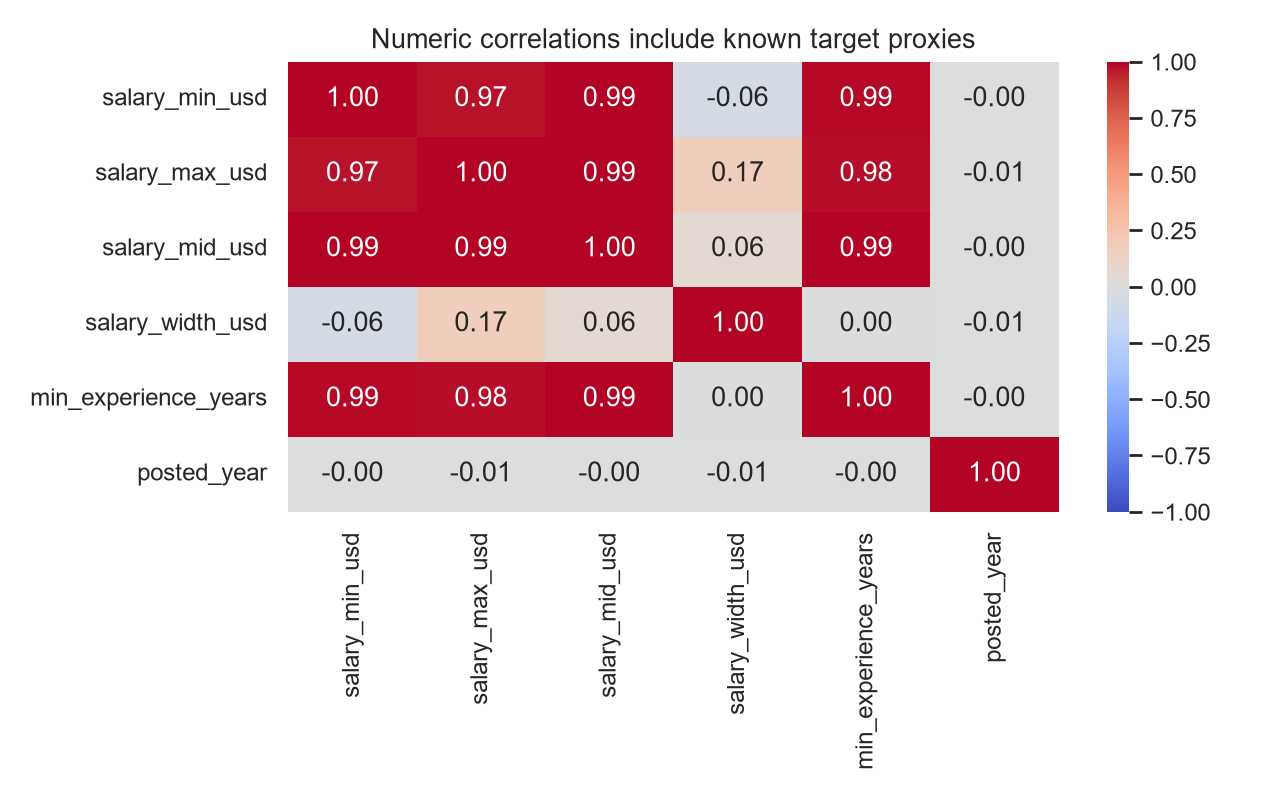

In [6]:
# Figure generated by the reproducible analysis pipeline: reports/figures/correlations.png


### Country Salary

Regenerate with `job-market analyze`.

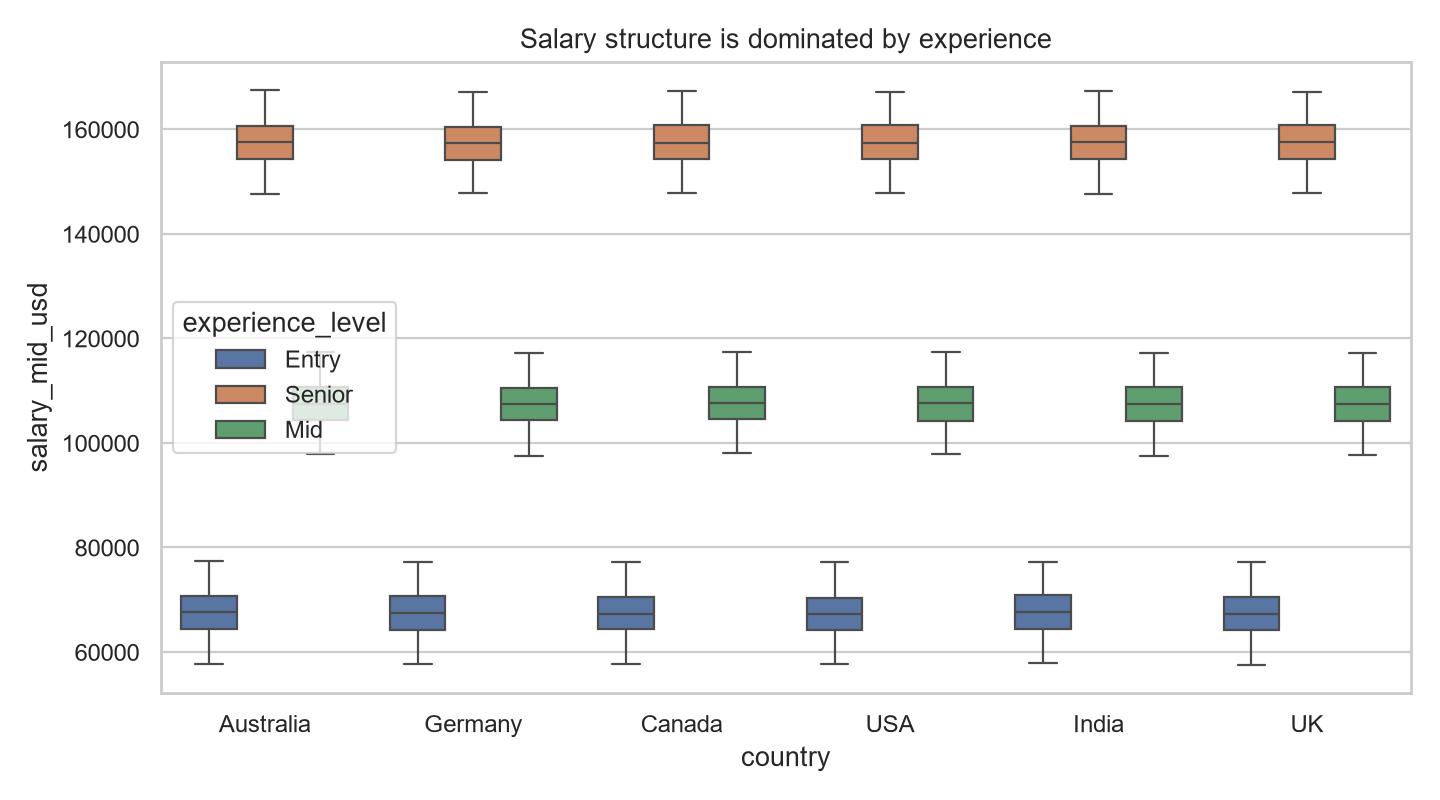

In [7]:
# Figure generated by the reproducible analysis pipeline: reports/figures/country_salary.png
